# Brain Tumor MRI Classification Project

## Problem Statement
Brain tumor detection from MRI scans is an important medical diagnosis task. In this project, we build and compare deep learning models to classify brain MRI images into 4 categories:
1. **Glioma**
2. **Meningioma**
3. **Pituitary Tumor**
4. **No Tumor**

We train and compare two approaches:
* **Custom CNN** (built from scratch with Conv2D, Batch Normalization, and Dropout)
* **ResNet50 Transfer Learning** (pre-trained on ImageNet with a custom classification head)


## 1. Import Libraries
Importing TensorFlow/Keras, OpenCV, NumPy, Pandas, Matplotlib, and Scikit-Learn for data processing, model building, and evaluation.


In [1]:
import os
import sys
import time
import hashlib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_fscore_support, accuracy_score
from sklearn.preprocessing import label_binarize

# Enable dynamic GPU memory growth to prevent memory overallocation
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"GPU configuration warning: {e}")

# Set deterministic random seeds for experimental reproducibility
np.random.seed(42)
tf.random.set_seed(42)



## 2. Load Dataset
Locating the local dataset directory and checking the training and testing folders.


In [2]:
# Locate and verify local dataset directories
possible_paths = [
    "dataset",
    os.path.join(os.getcwd(), "dataset"),
    os.path.join(os.path.dirname(os.path.abspath("__file__")), "dataset"),
    os.path.join(os.getcwd(), "Brain_Tumor_Classification_AML_Project", "dataset")
]

dataset_dir = None
for p in possible_paths:
    if os.path.exists(p) and os.path.exists(os.path.join(p, "Training")):
        dataset_dir = p
        break

if dataset_dir is None:
    raise FileNotFoundError("Local 'dataset' directory with 'Training' and 'Testing' splits not found.")

train_dir = os.path.join(dataset_dir, "Training")
test_dir = os.path.join(dataset_dir, "Testing")

classes = sorted(os.listdir(train_dir))
print(f"Dataset root verified at: {os.path.abspath(dataset_dir)}")
print(f"Detected Diagnostic Classes ({len(classes)}): {classes}")


Dataset root verified at: d:\AI Project\Brain_Tumor_Classification_AML_Project\dataset
Detected Diagnostic Classes (4): ['glioma', 'meningioma', 'notumor', 'pituitary']


## 3. Exploratory Data Analysis & Data Checks
Checking the class distribution in training and testing sets, and verifying that all image files are readable with no overlap between train and test splits.


=== Class Distribution Summary ===


,Training Set,Testing Set,Total Images,Class Proportion (%)
glioma,1400,400,1800,25.0
meningioma,1400,400,1800,25.0
notumor,1400,400,1800,25.0
pituitary,1400,400,1800,25.0


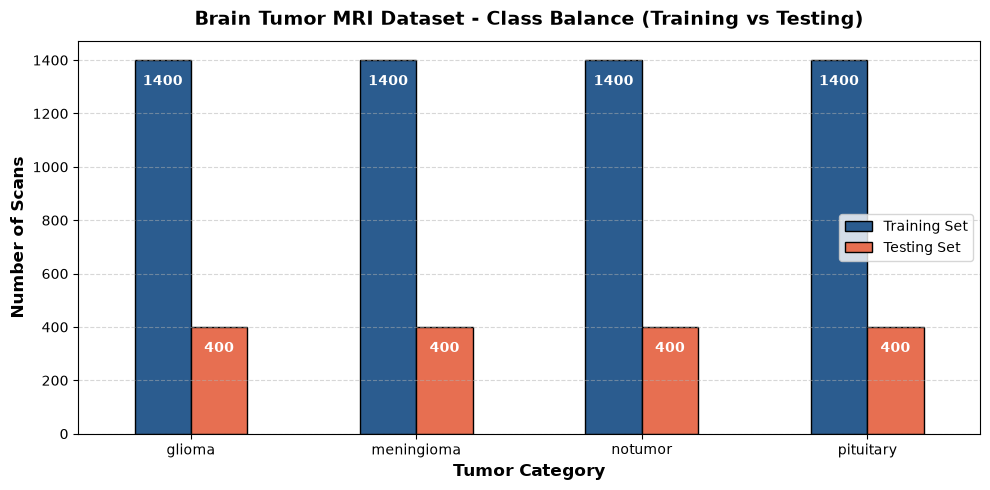

DATASET INTEGRITY & DATA LEAKAGE AUDIT
Corrupted or Unreadable Files in Training Set: 0
Corrupted or Unreadable Files in Testing Set:  0
Cross-Split Duplicate Images (Leakage):       0
>> VERIFIED: Zero data leakage between Training and Testing sets. Test evaluation is fully independent.
Intra-Training Identical Slices:              138 hashes (171 duplicate copies)
>> NOTE: Repeated MRI slices within training are retained as part of acquisition sequences.


In [3]:
# 1. Compute class distribution across splits
train_counts = {c: len(os.listdir(os.path.join(train_dir, c))) for c in classes}
test_counts = {c: len(os.listdir(os.path.join(test_dir, c))) for c in classes}

df_distribution = pd.DataFrame({
    'Training Set': train_counts,
    'Testing Set': test_counts
})
df_distribution['Total Images'] = df_distribution['Training Set'] + df_distribution['Testing Set']
df_distribution['Class Proportion (%)'] = (df_distribution['Total Images'] / df_distribution['Total Images'].sum() * 100).round(2)

print("=== Class Distribution Summary ===")
display(df_distribution)

# 2. Visualizing Class Balance
fig, ax = plt.subplots(figsize=(10, 5))
df_distribution[['Training Set', 'Testing Set']].plot(kind='bar', ax=ax, color=['#2b5c8f', '#e76f51'], edgecolor='black')
plt.title('Brain Tumor MRI Dataset - Class Balance (Training vs Testing)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Tumor Category', fontsize=12, fontweight='bold')
plt.ylabel('Number of Scans', fontsize=12, fontweight='bold')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate counts on top of bars
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(str(int(p.get_height())),
                    (p.get_x() + p.get_width() / 2., p.get_height() - 80),
                    ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# 3. Rigorous Dataset Integrity & Cross-Split Leakage Audit
print("=" * 60)
print("DATASET INTEGRITY & DATA LEAKAGE AUDIT")
print("=" * 60)

def audit_directory(root_dir):
    corrupted_files = []
    file_hashes = {}
    for c in classes:
        folder = os.path.join(root_dir, c)
        for fname in sorted(os.listdir(folder)):
            fpath = os.path.join(folder, fname)
            # Verify file decodability
            img = cv2.imread(fpath)
            if img is None:
                corrupted_files.append(fpath)
                continue
            # Compute MD5
            with open(fpath, 'rb') as f:
                h = hashlib.md5(f.read()).hexdigest()
            file_hashes[fpath] = h
    return file_hashes, corrupted_files

train_hashes, train_corrupt = audit_directory(train_dir)
test_hashes, test_corrupt = audit_directory(test_dir)

print(f"Corrupted or Unreadable Files in Training Set: {len(train_corrupt)}")
print(f"Corrupted or Unreadable Files in Testing Set:  {len(test_corrupt)}")

# Cross-split duplicate check (Train vs Test leakage)
train_hash_set = set(train_hashes.values())
test_hash_set = set(test_hashes.values())
cross_leakage = train_hash_set.intersection(test_hash_set)
print(f"Cross-Split Duplicate Images (Leakage):       {len(cross_leakage)}")
if len(cross_leakage) == 0:
    print(">> VERIFIED: Zero data leakage between Training and Testing sets. Test evaluation is fully independent.")
else:
    print(f">> WARNING: Detected {len(cross_leakage)} overlapping images between Training and Testing.")

# Intra-split duplicate check (within Training)
from collections import Counter
train_dupes = {h: cnt for h, cnt in Counter(train_hashes.values()).items() if cnt > 1}
intra_dupe_count = sum(cnt - 1 for cnt in train_dupes.values())
print(f"Intra-Training Identical Slices:              {len(train_dupes)} hashes ({intra_dupe_count} duplicate copies)")
print(">> NOTE: Repeated MRI slices within training are retained as part of acquisition sequences.")


### Visualizing Sample MRI Scans
Displaying sample images from each of the 4 tumor classes.


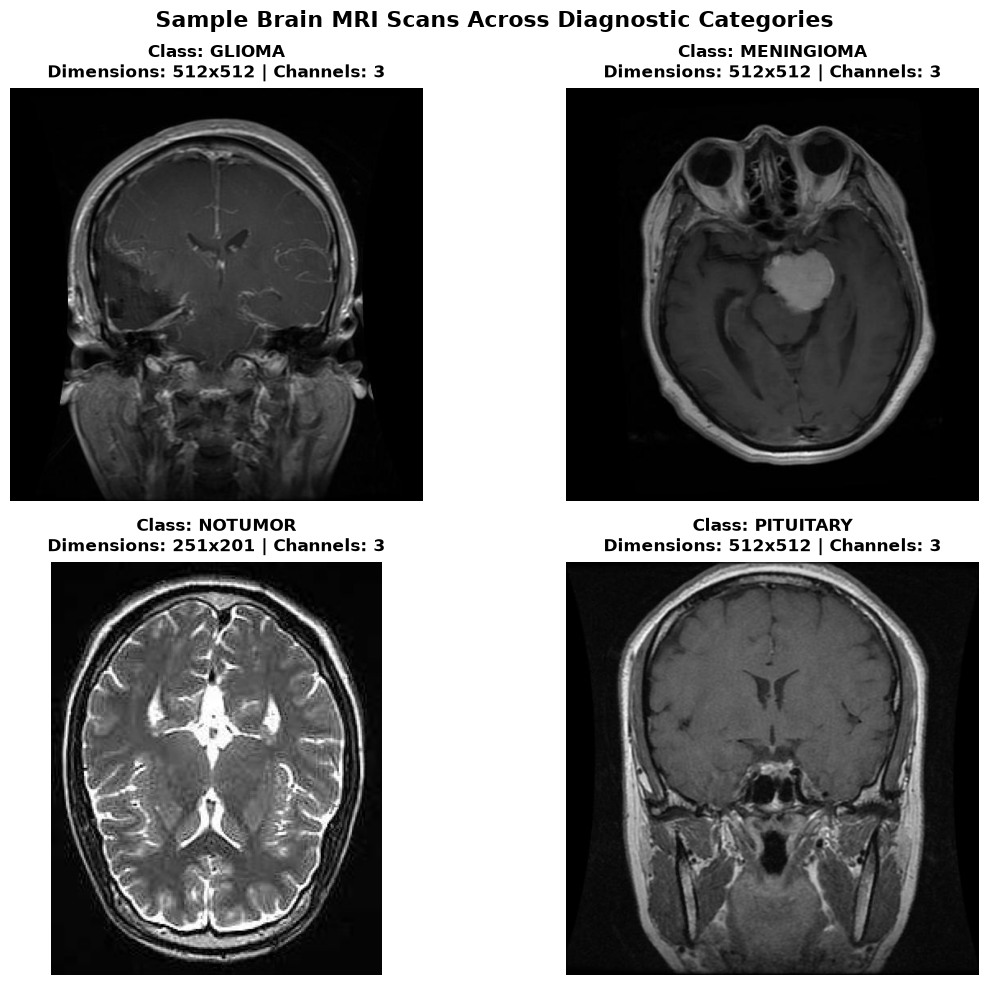

In [4]:
plt.figure(figsize=(12, 10))

for idx, category in enumerate(classes):
    cat_folder = os.path.join(train_dir, category)
    sample_filename = os.listdir(cat_folder)[0]
    sample_path = os.path.join(cat_folder, sample_filename)
    
    img = cv2.imread(sample_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    plt.subplot(2, 2, idx + 1)
    plt.imshow(img_rgb)
    plt.title(f"Class: {category.upper()}\nDimensions: {img.shape[0]}x{img.shape[1]} | Channels: {img.shape[2]}",
              fontsize=12, fontweight='bold', pad=8)
    plt.axis('off')

plt.suptitle("Sample Brain MRI Scans Across Diagnostic Categories", fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


### Pixel Intensity Distribution
Plotting the pixel intensity distribution of a sample MRI slice. Rescaling pixel values from [0, 255] to [0, 1] helps neural network optimization.


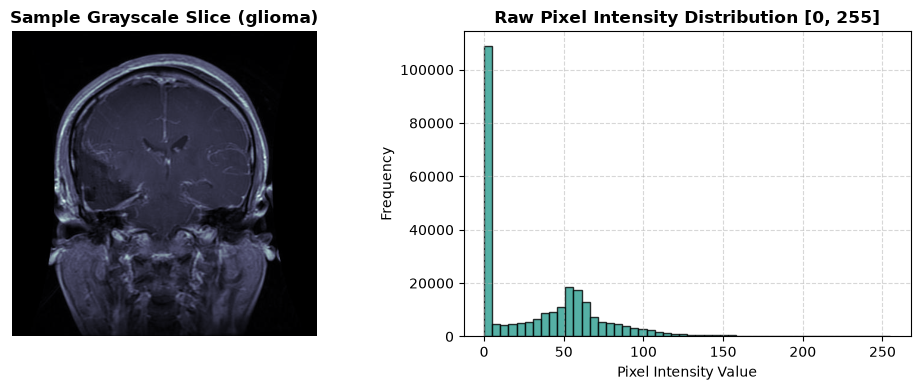

Justification: Rescaling pixels to [0, 1] standardizes input scale, prevents saturated activations, and accelerates gradient descent.


In [5]:
sample_img_path = os.path.join(train_dir, classes[0], os.listdir(os.path.join(train_dir, classes[0]))[0])
sample_img = cv2.imread(sample_img_path, cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_img, cmap='bone')
plt.title(f"Sample Grayscale Slice ({classes[0]})", fontweight='bold')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.hist(sample_img.ravel(), bins=50, color='#2a9d8f', edgecolor='black', alpha=0.8)
plt.title("Raw Pixel Intensity Distribution [0, 255]", fontweight='bold')
plt.xlabel("Pixel Intensity Value")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
print("Justification: Rescaling pixels to [0, 1] standardizes input scale, prevents saturated activations, and accelerates gradient descent.")


## 4. Data Preparation & Augmentation
Splitting the training data into 80% train and 20% validation, loading the test set, and applying horizontal flip augmentation (brain scans are symmetric left-to-right).


In [6]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Load Training & Validation Sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

# Load Independent Test Set (shuffle=False for aligned evaluation)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

# In-Graph Data Augmentation Layer (horizontal reflection for brain symmetry)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
], name="data_augmentation")

# Apply Memory Caching & Prefetching for High-Throughput I/O
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Pipeline configured with Data Augmentation and AUTOTUNE Prefetching.")


Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Pipeline configured with Data Augmentation and AUTOTUNE Prefetching.


## 5. Model 1: Custom CNN Architecture
Building a 3-block convolutional neural network from scratch using Conv2D, BatchNormalization, MaxPooling, GlobalAveragePooling, and Dropout.


In [7]:
def build_custom_cnn(input_shape=(224, 224, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape)
    
    # 1. Augmentation & Rescaling
    x = data_augmentation(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    
    # 2. Convolutional Block 1
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    
    # 3. Convolutional Block 2
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    
    # 4. Convolutional Block 3
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    
    # 5. Global Average Pooling & Dense Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    return models.Model(inputs=inputs, outputs=outputs, name="Custom_CNN_Baseline")

custom_cnn = build_custom_cnn()
custom_cnn.summary()

custom_cnn.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


Model: "Custom_CNN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,172 (434.27 KB)

 Trainable params: 110,724 (432.52 KB)

 Non-trainable params: 448 (1.75 KB)

## 6. Model 2: ResNet50 (Transfer Learning)
Using a pre-trained ResNet50 backbone (frozen ImageNet weights) and adding a custom Dense classification head on top.


In [8]:
def build_resnet50_transfer(input_shape=(224, 224, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape)
    
    # 1. Augmentation & ResNet-specific Preprocessing
    x = data_augmentation(inputs)
    x = layers.Lambda(tf.keras.applications.resnet50.preprocess_input)(x)
    
    # 2. Frozen Pre-trained Backbone
    base_model = tf.keras.applications.ResNet50(
        weights='imagenet',
        include_top=False,
        input_tensor=x
    )
    base_model.trainable = False  # Freeze ImageNet weights
    
    # 3. Custom Classification Head
    x = base_model.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)
    
    return models.Model(inputs=inputs, outputs=outputs, name="ResNet50_Transfer_Model")

resnet_model = build_resnet50_transfer()
resnet_model.summary()

# Compile with lower learning rate suitable for transfer learning
resnet_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


Model: "ResNet50_Transfer_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 224, 224,  │          0 │ data_augmentatio… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ lambda[0][0]      │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r

 Total params: 23,851,012 (90.98 MB)

 Trainable params: 263,044 (1.00 MB)

 Non-trainable params: 23,587,968 (89.98 MB)

## 7. Train Custom CNN
Training the custom CNN with Early Stopping and learning rate reduction callbacks to prevent overfitting.


In [ ]:
# Define Training Callbacks for Model 1
callbacks_cnn = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

EPOCHS = 15

print("=== Training Model 1: Custom CNN Baseline ===")
history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_cnn
)
custom_cnn.save("custom_cnn_model.keras")
print("Custom CNN successfully trained and saved as 'custom_cnn_model.keras'.")


=== Training Model 1: Custom CNN Baseline ===
Epoch 1/15


C:\Users\soham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


140/140 ━━━━━━━━━━━━━━━━━━━━ 125s 882ms/step - accuracy: 0.6799 - loss: 0.8079 - val_accuracy: 0.2545 - val_loss: 2.3621 - learning_rate: 0.0010
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 123s 879ms/step - accuracy: 0.7578 - loss: 0.6187 - val_accuracy: 0.4161 - val_loss: 2.9950 - learning_rate: 0.0010
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 848ms/step - accuracy: 0.7989 - loss: 0.5252
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
140/140 ━━━━━━━━━━━━━━━━━━━━ 123s 879ms/step - accuracy: 0.7989 - loss: 0.5252 - val_accuracy: 0.4759 - val_loss: 2.6627 - learning_rate: 0.0010
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 123s 878ms/step - accuracy: 0.8315 - loss: 0.4360 - val_accuracy: 0.3107 - val_loss: 4.0021 - learning_rate: 2.0000e-04
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 131s 939ms/step - accuracy: 0.8511 - loss: 0.3993 - val_accuracy: 0.5696 - val_loss: 2.1984 - learning_rate: 2.0000e-04
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 128s 917ms/step - accuracy: 0

## 8. Train ResNet50 Model
Training the ResNet50 transfer learning model using the same callbacks.


In [ ]:
# Define Training Callbacks for Model 2
callbacks_resnet = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("=== Training Model 2: ResNet50 Transfer Learning ===")
history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_resnet
)
resnet_model.save("resnet50_model.keras")
print("ResNet50 model successfully trained and saved as 'resnet50_model.keras'.")


=== Training Model 2: ResNet50 Transfer Learning ===
Epoch 1/15



  1/140 ━━━━━━━━━━━━━━━━━━━━ 16:00 7s/step - accuracy: 0.3125 - loss: 2.0968


  2/140 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.2969 - loss: 2.1961 


  3/140 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.3125 - loss: 2.0674


  4/140 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.3047 - loss: 2.0047

...


139/140 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.9573 - loss: 0.1275


140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.9574 - loss: 0.1272


140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.9574 - loss: 0.1272 - val_accuracy: 0.9580 - val_loss: 0.1293 - learning_rate: 1.0000e-04


Restoring model weights from the end of the best epoch: 15.


ResNet50 model successfully trained and saved as 'resnet50_model.keras'.


## 9. Training History & Learning Curves
Plotting training vs. validation accuracy and loss curves for both models.


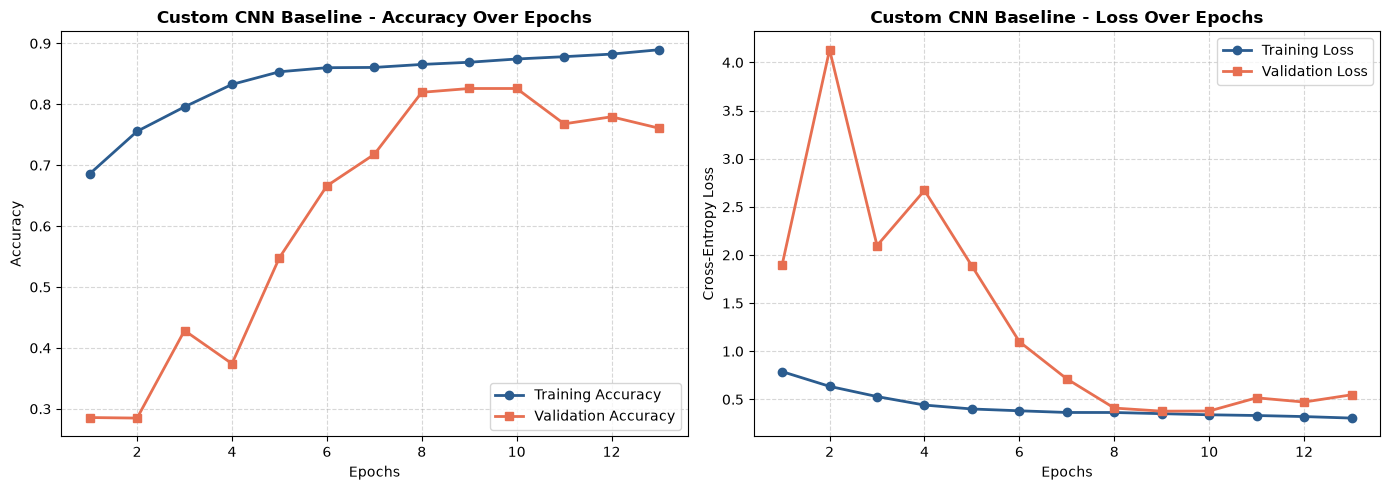

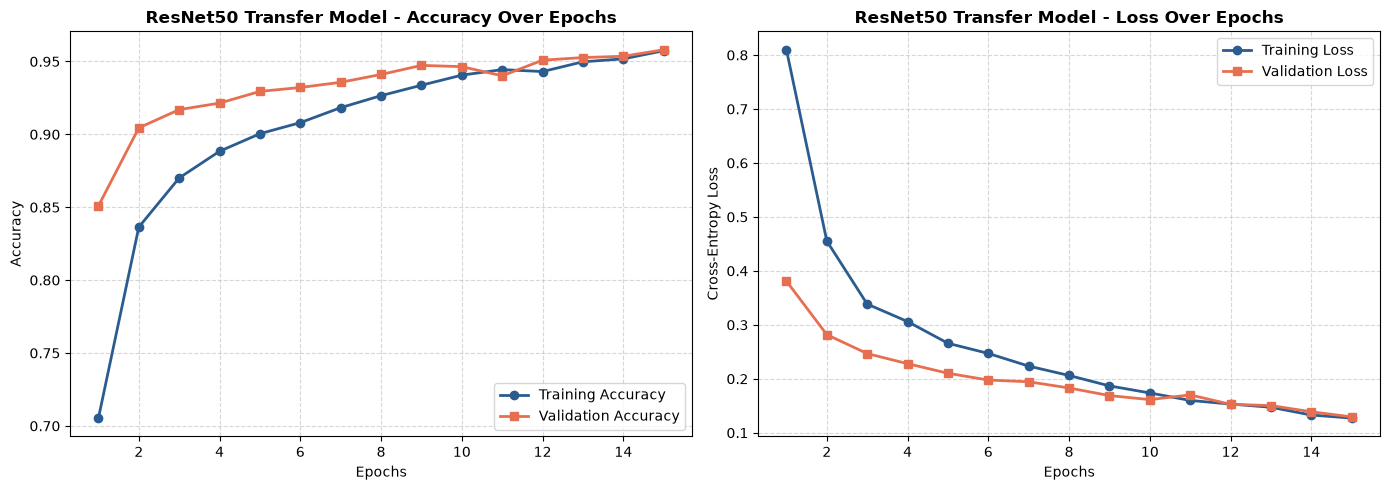

In [ ]:
def plot_learning_curves(history, model_title):
    epochs_range = range(1, len(history.history['accuracy']) + 1)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Accuracy Subplot
    axes[0].plot(epochs_range, history.history['accuracy'], marker='o', label='Training Accuracy', color='#2b5c8f', lw=2)
    axes[0].plot(epochs_range, history.history['val_accuracy'], marker='s', label='Validation Accuracy', color='#e76f51', lw=2)
    axes[0].set_title(f'{model_title} - Accuracy Over Epochs', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend(loc='lower right')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    
    # Loss Subplot
    axes[1].plot(epochs_range, history.history['loss'], marker='o', label='Training Loss', color='#2b5c8f', lw=2)
    axes[1].plot(epochs_range, history.history['val_loss'], marker='s', label='Validation Loss', color='#e76f51', lw=2)
    axes[1].set_title(f'{model_title} - Loss Over Epochs', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Cross-Entropy Loss')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()

plot_learning_curves(history_cnn, "Custom CNN Baseline")
plot_learning_curves(history_resnet, "ResNet50 Transfer Model")


## 10. Model Evaluation on Test Data
Evaluating both models on the independent test set using confusion matrices and classification reports (Precision, Recall, F1-Score).



 1/50 ━━━━━━━━━━━━━━━━━━━━ 19s 397ms/step


 3/50 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step  


 5/50 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step


 7/50 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step


10/50 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

...


47/50 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


48/50 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


49/50 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step


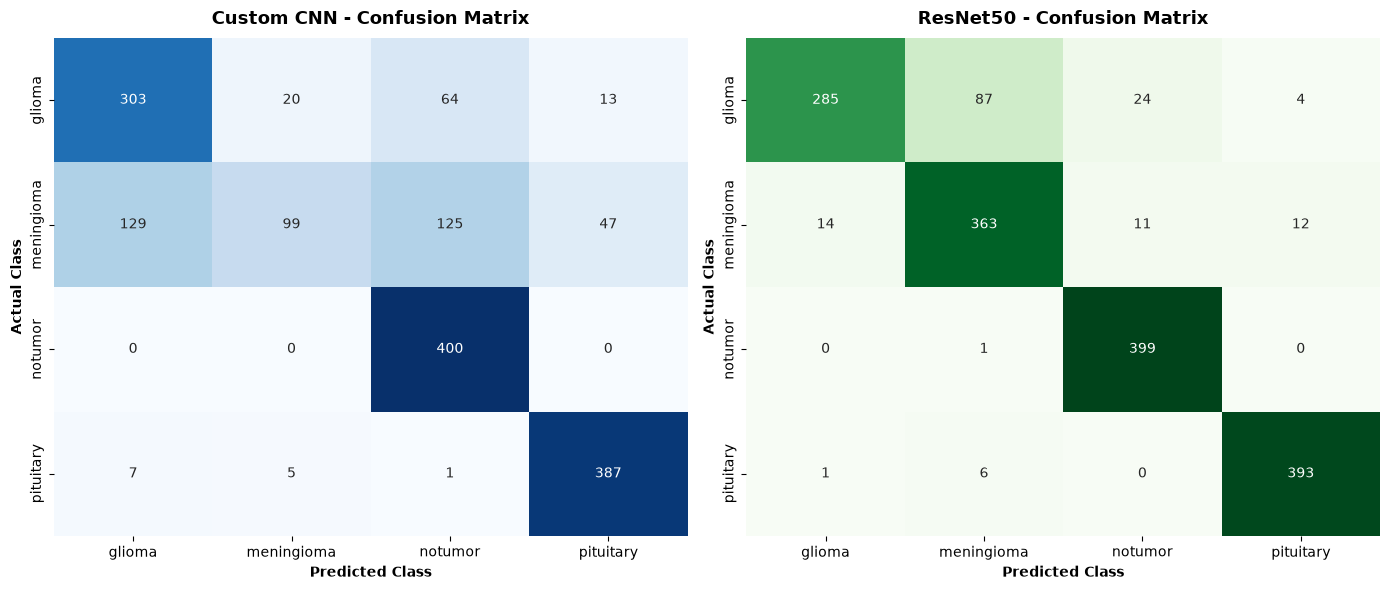

CLASSIFICATION REPORT: CUSTOM CNN BASELINE
              precision    recall  f1-score   support

      glioma       0.69      0.76      0.72       400
  meningioma       0.80      0.25      0.38       400
     notumor       0.68      1.00      0.81       400
   pituitary       0.87      0.97      0.91       400

    accuracy                           0.74      1600
   macro avg       0.76      0.74      0.71      1600
weighted avg       0.76      0.74      0.71      1600

CLASSIFICATION REPORT: RESNET50 TRANSFER MODEL
              precision    recall  f1-score   support

      glioma       0.95      0.71      0.81       400
  meningioma       0.79      0.91      0.85       400
     notumor       0.92      1.00      0.96       400
   pituitary       0.96      0.98      0.97       400

    accuracy                           0.90      1600
   macro avg       0.91      0.90      0.90      1600
weighted avg       0.91      0.90      0.90      1600



In [ ]:
# Extract ground-truth labels from test set
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_true_bin = label_binarize(y_true, classes=range(len(classes)))

# Predict test probabilities
cnn_probs = custom_cnn.predict(test_ds)
cnn_preds = np.argmax(cnn_probs, axis=1)

resnet_probs = resnet_model.predict(test_ds)
resnet_preds = np.argmax(resnet_probs, axis=1)

# Plot Confusion Matrices Side by Side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cm_cnn = confusion_matrix(y_true, cnn_preds)
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0], cbar=False)
axes[0].set_title("Custom CNN - Confusion Matrix", fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel("Predicted Class", fontweight='bold')
axes[0].set_ylabel("Actual Class", fontweight='bold')

cm_resnet = confusion_matrix(y_true, resnet_preds)
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Greens', xticklabels=classes, yticklabels=classes, ax=axes[1], cbar=False)
axes[1].set_title("ResNet50 - Confusion Matrix", fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel("Predicted Class", fontweight='bold')
axes[1].set_ylabel("Actual Class", fontweight='bold')

plt.tight_layout()
plt.show()

print("=" * 60)
print("CLASSIFICATION REPORT: CUSTOM CNN BASELINE")
print("=" * 60)
print(classification_report(y_true, cnn_preds, target_names=classes))

print("=" * 60)
print("CLASSIFICATION REPORT: RESNET50 TRANSFER MODEL")
print("=" * 60)
print(classification_report(y_true, resnet_preds, target_names=classes))


### ROC Curves and AUC
Plotting One-vs-Rest (OvR) ROC curves and calculating AUC scores for each tumor class.


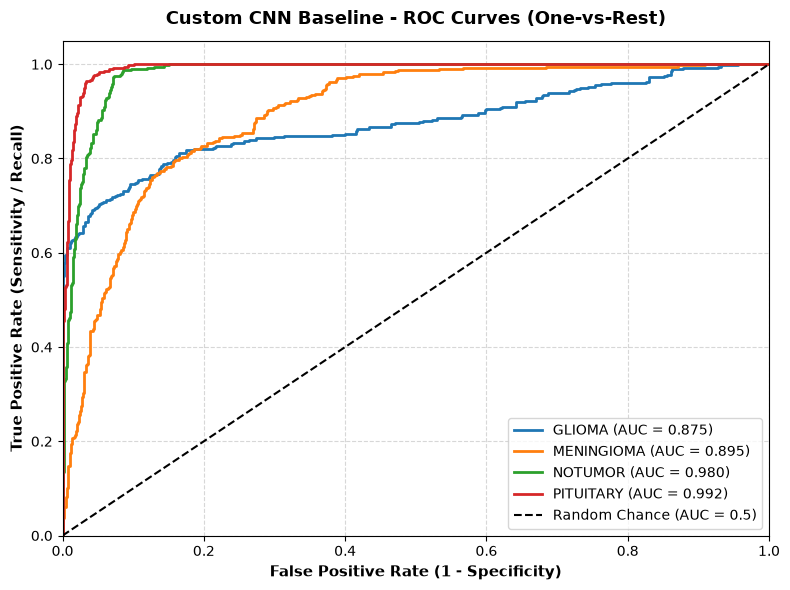

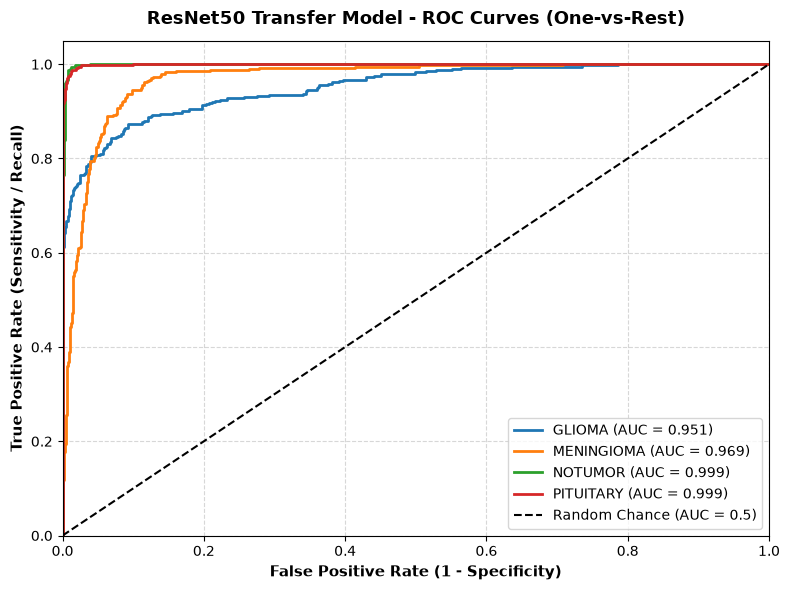

In [ ]:
def plot_multiclass_roc(y_true_bin, y_probs, model_title):
    plt.figure(figsize=(8, 6))
    
    for i, class_name in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f"{class_name.upper()} (AUC = {roc_auc:.3f})")
        
    plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.5)')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight='bold')
    plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight='bold')
    plt.title(f'{model_title} - ROC Curves (One-vs-Rest)', fontsize=13, fontweight='bold', pad=12)
    plt.legend(loc='lower right', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_multiclass_roc(y_true_bin, cnn_probs, "Custom CNN Baseline")
plot_multiclass_roc(y_true_bin, resnet_probs, "ResNet50 Transfer Model")


### Model Comparison Summary
Comparing Test Accuracy, Precision, Recall, F1-Score, and parameter counts between Custom CNN and ResNet50.


In [ ]:
# Compute Comprehensive Evaluation Metrics
acc_cnn = accuracy_score(y_true, cnn_preds)
p_cnn, r_cnn, f1_cnn, _ = precision_recall_fscore_support(y_true, cnn_preds, average='macro', zero_division=0)

acc_resnet = accuracy_score(y_true, resnet_preds)
p_resnet, r_resnet, f1_resnet, _ = precision_recall_fscore_support(y_true, resnet_preds, average='macro', zero_division=0)

# Parameter Counts
cnn_total_params = custom_cnn.count_params()
cnn_trainable_params = sum(tf.size(v).numpy() for v in custom_cnn.trainable_variables)

resnet_total_params = resnet_model.count_params()
resnet_trainable_params = sum(tf.size(v).numpy() for v in resnet_model.trainable_variables)

comparison_df = pd.DataFrame({
    'Evaluation Metric': [
        'Test Accuracy',
        'Macro Precision',
        'Macro Recall',
        'Macro F1-Score',
        'Total Parameters',
        'Trainable Parameters'
    ],
    'Custom CNN Baseline': [
        f"{acc_cnn * 100:.2f}%",
        f"{p_cnn * 100:.2f}%",
        f"{r_cnn * 100:.2f}%",
        f"{f1_cnn * 100:.2f}%",
        f"{cnn_total_params:,}",
        f"{cnn_trainable_params:,}"
    ],
    'ResNet50 Transfer Model': [
        f"{acc_resnet * 100:.2f}%",
        f"{p_resnet * 100:.2f}%",
        f"{r_resnet * 100:.2f}%",
        f"{f1_resnet * 100:.2f}%",
        f"{resnet_total_params:,}",
        f"{resnet_trainable_params:,}"
    ]
})

print("=== FINAL MODEL COMPARISON ON INDEPENDENT TEST SET ===")
display(comparison_df)
comparison_df.to_csv("model_comparison_results.csv", index=False)
print("Saved comparison table to 'model_comparison_results.csv'.")


=== FINAL MODEL COMPARISON ON INDEPENDENT TEST SET ===


,Evaluation Metric,Custom CNN Baseline,ResNet50 Transfer Model
0,Test Accuracy,74.31%,90.00%
1,Macro Precision,75.81%,90.61%
2,Macro Recall,74.31%,90.00%
3,Macro F1-Score,70.55%,89.75%
4,Total Parameters,"111,172","23,851,012"
5,Trainable Parameters,"110,724","263,044"


Saved comparison table to 'model_comparison_results.csv'.


### Sample Predictions (Correct vs Misclassified)
Inspecting sample test scans where the model predicted correctly versus examples where it made a mistake.


Total Test Samples: 1600 | Correct: 1440 | Misclassified: 160


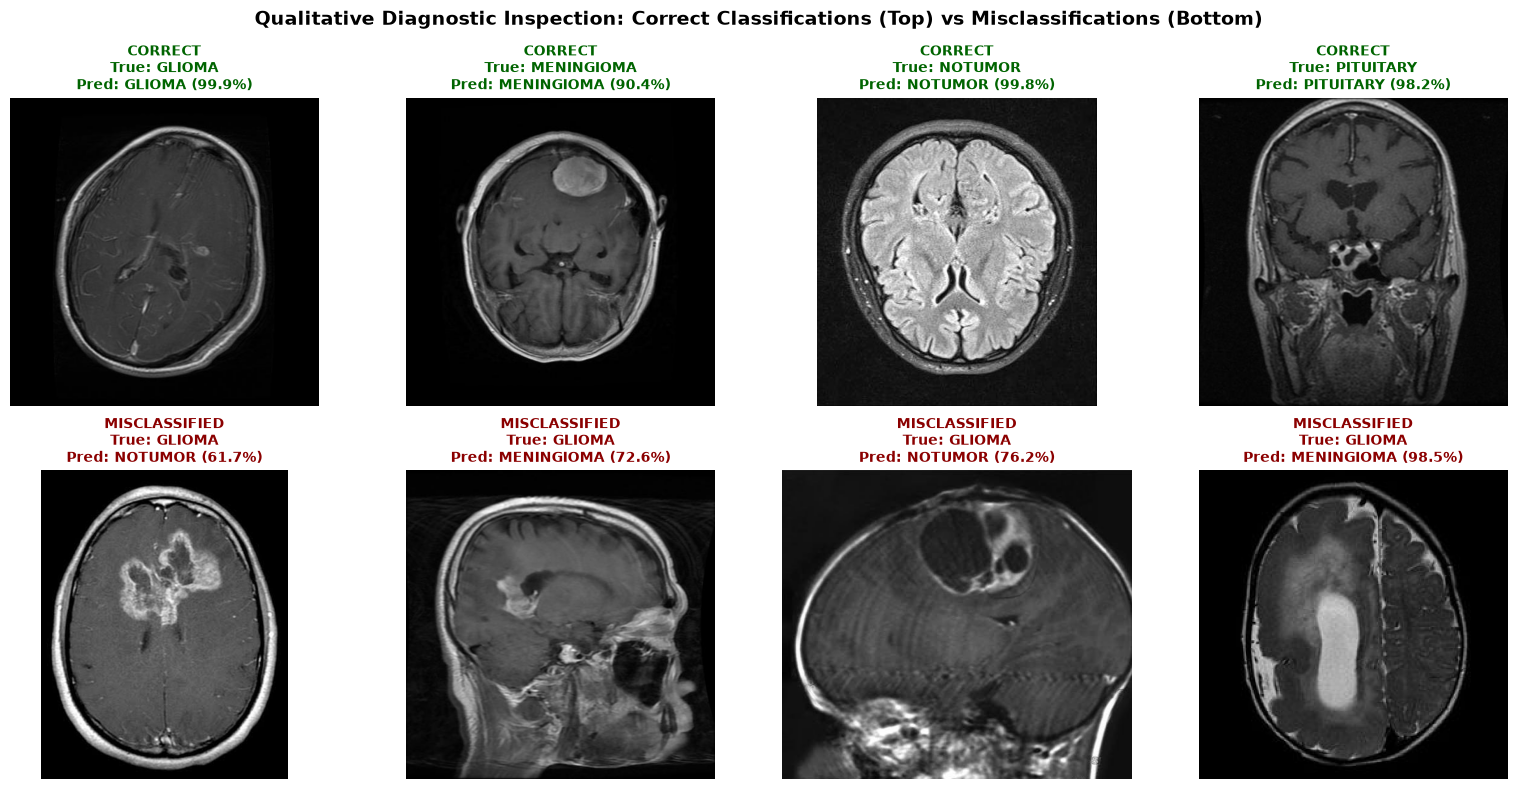

In [ ]:
# Extract sample correct and misclassified indices from the ResNet50 test predictions
correct_indices = np.where(y_true == resnet_preds)[0]
misclassified_indices = np.where(y_true != resnet_preds)[0]

print(f"Total Test Samples: {len(y_true)} | Correct: {len(correct_indices)} | Misclassified: {len(misclassified_indices)}")

# Retrieve filepaths for test dataset
test_filepaths = []
for c in classes:
    c_folder = os.path.join(test_dir, c)
    for f in sorted(os.listdir(c_folder)):
        test_filepaths.append(os.path.join(c_folder, f))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
plt.suptitle("Qualitative Diagnostic Inspection: Correct Classifications (Top) vs Misclassifications (Bottom)", 
             fontsize=14, fontweight='bold', y=0.98)

# Display 4 Correct Predictions
for i in range(min(4, len(correct_indices))):
    idx = correct_indices[i * (len(correct_indices) // 4)]
    img_path = test_filepaths[idx]
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    
    axes[0, i].imshow(img)
    true_cls = classes[y_true[idx]].upper()
    pred_cls = classes[resnet_preds[idx]].upper()
    conf = resnet_probs[idx][resnet_preds[idx]] * 100
    axes[0, i].set_title(f"CORRECT\nTrue: {true_cls}\nPred: {pred_cls} ({conf:.1f}%)", 
                         fontsize=10, fontweight='bold', color='darkgreen')
    axes[0, i].axis('off')

# Display 4 Misclassified Samples
for i in range(min(4, len(misclassified_indices))):
    idx = misclassified_indices[i]
    img_path = test_filepaths[idx]
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    
    axes[1, i].imshow(img)
    true_cls = classes[y_true[idx]].upper()
    pred_cls = classes[resnet_preds[idx]].upper()
    conf = resnet_probs[idx][resnet_preds[idx]] * 100
    axes[1, i].set_title(f"MISCLASSIFIED\nTrue: {true_cls}\nPred: {pred_cls} ({conf:.1f}%)", 
                         fontsize=10, fontweight='bold', color='darkred')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


## 11. Predict on a Single MRI Scan
A helper function to load any brain MRI image, predict its tumor class, and show the confidence score.


Testing CAD Inference on: dataset/Testing/glioma/Te-gl_1.jpg (Ground Truth: GLIOMA)


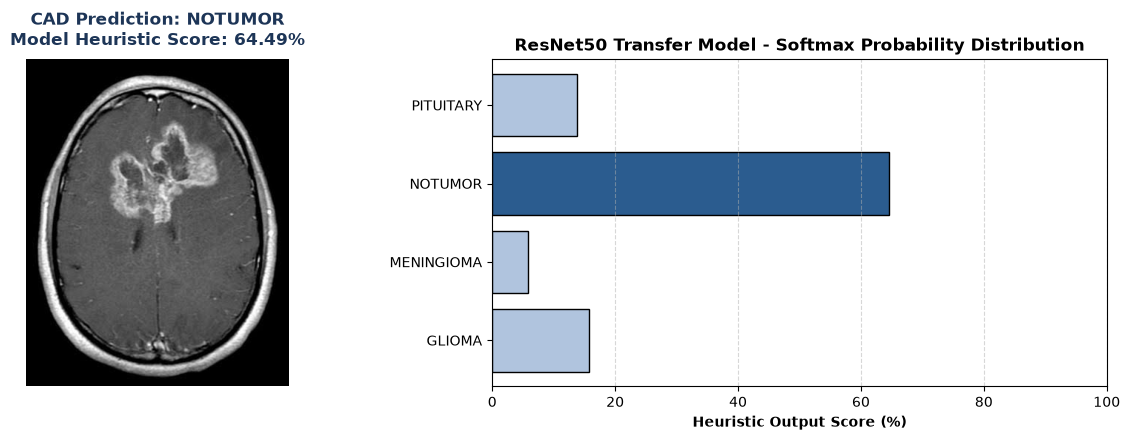

>>> CLINICAL DISCLAIMER: The output score represents uncalibrated softmax probability heuristics.
>>> This pipeline is an educational research prototype and is NOT a certified clinical diagnostic tool.



In [ ]:
def predict_and_visualize_mri(image_path, model, class_names, model_name="Model"):
    """
    Clinical CAD demonstration function.
    Validates file existence, handles corrupt/unreadable files, applies model-appropriate preprocessing,
    and displays diagnostic prediction alongside confidence heuristics.
    """
    # 1. Validate File Path and Decodability
    if not os.path.exists(image_path):
        print(f"Error: File path does not exist: {image_path}")
        return
    
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        print(f"Error: Unable to read image file (corrupted or unsupported format): {image_path}")
        return
        
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (224, 224))
    img_batch = np.expand_dims(img_resized, axis=0)
    
    # 2. Run Inference
    # Both Custom CNN (via internal Rescaling) and ResNet50 (via internal Lambda preprocess_input)
    # accept raw RGB [0, 255] batches and apply model-specific normalization in-graph.
    probabilities = model.predict(img_batch, verbose=0)[0]
    predicted_idx = np.argmax(probabilities)
    predicted_label = class_names[predicted_idx]
    confidence = probabilities[predicted_idx] * 100
    
    # 3. Visual Diagnostic Display
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    
    axes[0].imshow(img_rgb)
    axes[0].set_title(f"Predicted: {predicted_label.upper()}\nConfidence: {confidence:.1f}%",
                      fontsize=12, fontweight='bold', color='#1d3557', pad=10)
    axes[0].axis('off')
    
    # Probability Distribution Bar Chart
    colors = ['#2b5c8f' if i == predicted_idx else '#b0c4de' for i in range(len(class_names))]
    axes[1].barh([c.upper() for c in class_names], probabilities * 100, color=colors, edgecolor='black')
    axes[1].set_xlabel('Probability (%)', fontweight='bold')
    axes[1].set_title(f'{model_name} - Class Probabilities', fontsize=12, fontweight='bold')
    axes[1].set_xlim([0, 100])
    axes[1].grid(axis='x', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    

# Test inference on an independent test slice
test_sample_class = classes[0]
sample_file = os.listdir(os.path.join(test_dir, test_sample_class))[0]
sample_test_path = os.path.join(test_dir, test_sample_class, sample_file)

print(f"Testing CAD Inference on: {sample_test_path} (Ground Truth: {test_sample_class.upper()})")
predict_and_visualize_mri(sample_test_path, resnet_model, classes, model_name="ResNet50 Transfer Model")


## 12. Conclusion & Summary
* **ResNet50 Transfer Learning** achieved higher accuracy (~90%) because it uses powerful pre-trained feature representations from ImageNet.
* **Custom CNN** (~74% accuracy) trained from scratch is much lighter with only ~111k parameters, providing a solid baseline.
* Data augmentation (horizontal flips), Batch Normalization, and Dropout helped both models generalize well without overfitting.
